# 05. Model development, evaluation, and temporal validation

This notebook develops and evaluates the metabolic-syndrome classification
models after notebooks 01–04 have created the corrected analytic dataset.

Key safeguards in this version:

- Average precision (AP), used for hyperparameter search, is kept distinct from
  the area under the precision-recall curve (PR-AUC/AUPRC).
- The test set is not used for hyperparameter tuning, threshold selection, or
  calibration-method selection.
- Random Forest is retained as the authors' final algorithm; model comparisons
  are reported rather than used to retroactively justify that choice.
- Temporal validation re-tunes the Random Forest using 2021–2023 data only
  before evaluating 2024.
- Range-exclusion and deterministic weight-control-composite sensitivity
  analyses are included.
- No table or figure is presented as a strategy for deciding who should
  receive biochemical testing, because biochemical variables are model inputs.


In [1]:
import os
from pathlib import Path
from math import prod

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    auc, f1_score, brier_score_loss, confusion_matrix, accuracy_score
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# LightGBM is one of the candidate algorithms.
from lightgbm import LGBMClassifier

# Use environment-based paths for reproducibility.
BASE = Path(os.environ.get("METS_DATA", r"D:\eda\mets\data"))
OUT  = Path(os.environ.get("METS_OUT",  r"D:\eda\mets\output"))
for _d in (BASE, BASE/"raw", BASE/"work", OUT, OUT/"tables", OUT/"figures", OUT/"logs"):
    _d.mkdir(parents=True, exist_ok=True)
OUT_T = OUT / "tables"
OUT_F = OUT / "figures"

SEED     = 42
TARGET   = "MS"
CV_FOLDS = 5
MAX_SEARCH_DRAWS = 40
N_BOOT   = 2000
THR_GRID = np.round(np.arange(0.05, 0.96, 0.01), 2)

# The revised analysis retains Random Forest as the authors' final algorithm.
# This is not labelled "prespecified" because no dated, version-controlled
# record establishing a pre-analysis choice is available.
FINAL_NAME = "Random forest"
MODEL_SELECTION_RATIONALE = (
    "Random Forest was retained as the final model in the revised analysis "
    "on methodological grounds rather than solely on a single cross-validated "
    "performance measure."
)

# Nineteen candidate predictors. Metabolic-syndrome components used to define
# the outcome (waist circumference, BP, HDL, TG, glucose) are excluded.
FEATURES = [
    "sex", "age", "global_grade", "bmi",
    "chol", "LDL", "AST", "ALT",
    "sleep", "PA", "EatingIndex",
    "weight_control_diet", "weight_control_exercise",
    "weight_control_medication", "weight_control_attempt",
    "bully", "runaway", "want_counseling", "request_counseling",
]

DISPLAY_NAME = {
    "sex": "Sex (1 = male)",
    "age": "Age, years",
    "global_grade": "School level",
    "bmi": "Body mass index",
    "chol": "Total cholesterol",
    "LDL": "LDL cholesterol",
    "AST": "Aspartate aminotransferase",
    "ALT": "Alanine aminotransferase",
    "sleep": "Sleep",
    "PA": "Physical activity",
    "EatingIndex": "Eating habit index",
    "weight_control_diet": "Weight-control dieting",
    "weight_control_exercise": "Weight-control exercise",
    "weight_control_medication": "Weight-control medication",
    "weight_control_attempt": "Any weight-control attempt",
    "bully": "Bullying victimization",
    "runaway": "Thoughts of running away",
    "want_counseling": "Counseling need, school or home problems",
    "request_counseling": "Counseling need, personal worries",
}
assert set(DISPLAY_NAME) == set(FEATURES)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "Arial", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})

def save_fig(fig, name):
    for ext in ("tif", "png"):
        fig.savefig(
            OUT_F/f"{name}.{ext}", dpi=300, bbox_inches="tight",
            pil_kwargs={"compression": "tiff_lzw"} if ext == "tif" else None
        )
    print(f"  saved -> {name}.tif / .png")

def pr_auc_score(y_true, p):
    """Trapezoidal area under the empirical precision-recall curve."""
    precision, recall, _ = precision_recall_curve(y_true, p)
    return float(auc(recall, precision))

df = pd.read_csv(BASE/"work"/"Obesity_Data_proprecessing_OUTLIER.csv")
missing = [c for c in FEATURES + [TARGET, "year"] if c not in df.columns]
assert not missing, f"required analysis column(s) absent: {missing}"
print(f"n = {len(df):,}   candidate predictors = {len(FEATURES)}")

X = df[FEATURES].copy()
y = df[TARGET].astype(int)
print(f"MetS {int(y.sum()):,} ({y.mean()*100:.2f}%)")


n = 13,670   candidate predictors = 19
MetS 1,730 (12.66%)


## 1. Training and test split

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
idx_te = X_te.index

print(f"train {len(X_tr):,}  (MetS {int(y_tr.sum()):,}, {y_tr.mean()*100:.2f}%)")
print(f"test  {len(X_te):,}  (MetS {int(y_te.sum()):,}, {y_te.mean()*100:.2f}%)")
print(f"all-negative accuracy reference = {1-y_te.mean():.4f}")

cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)


train 10,936  (MetS 1,384, 12.66%)
test  2,734  (MetS 346, 12.66%)
all-negative accuracy reference = 0.8734


## 2. Candidate models and search spaces

In [3]:
# Candidate estimators and search spaces; scaling stays inside logistic CV folds.
CANDIDATES = {
    "Logistic regression": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000,
                                             class_weight="balanced"))]),
        {"clf__C": np.logspace(-3, 2, 20),
         "clf__penalty": ["l2"],
         "clf__solver": ["lbfgs"]},
    ),
    "Random forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"n_estimators": [300, 500, 800],
         "max_depth": [10, 15, 20, None],
         "min_samples_split": [5, 10, 15],
         "min_samples_leaf": [2, 4, 8],
         "max_features": ["sqrt", "log2"],
         "criterion": ["gini", "entropy"]},
    ),
}
# Preserve the searched LightGBM grid for exact reproducibility.
CANDIDATES["LightGBM"] = (
    LGBMClassifier(class_weight="balanced", random_state=SEED,
                   n_jobs=-1, verbose=-1),
    {"n_estimators": [300, 500, 800],
     "learning_rate": [0.01, 0.03, 0.05, 0.1],
     "num_leaves": [15, 31, 63],
     "max_depth": [-1, 5, 8],
     "min_child_samples": [10, 20, 40],
     "subsample": [0.7, 0.85, 1.0],
     "colsample_bytree": [0.7, 0.85, 1.0]},
)

print("candidate models:", list(CANDIDATES))


candidate models: ['Logistic regression', 'Random forest', 'LightGBM']


## 3. Search and cross-validated selection

In [4]:
def pick_threshold(y_true, p, grid=THR_GRID):
    f1 = [f1_score(y_true, (p >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1))]), np.asarray(f1)

def search_draws(space, cap=MAX_SEARCH_DRAWS):
    """Use at most `cap` unique configurations; avoids claiming 40 for a 20-point grid."""
    total = prod(len(v) for v in space.values())
    return int(min(cap, total))

def tune_estimator(est, space, X_train, y_train, cv_obj):
    n_iter = search_draws(space)
    search = RandomizedSearchCV(
        est, space, n_iter=n_iter, cv=cv_obj,
        scoring="average_precision", n_jobs=-1,
        random_state=SEED, refit=True
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_
    oof = cross_val_predict(
        clone(best), X_train, y_train, cv=cv_obj,
        method="predict_proba", n_jobs=-1
    )[:, 1]
    thr, _ = pick_threshold(y_train, oof)
    return search, best, oof, thr

results, fitted, fold_scores = {}, {}, {}
for name, (est, space) in CANDIDATES.items():
    print(f"\n[{name}] searching...")
    search, best, oof, thr = tune_estimator(est, space, X_tr, y_tr, cv)

    # RandomizedSearchCV uses average precision (AP), not trapezoidal PR-AUC.
    folds = np.asarray([
        search.cv_results_[f"split{k}_test_score"][search.best_index_]
        for k in range(CV_FOLDS)
    ], dtype=float)
    fold_scores[name] = folds

    results[name] = {
        "best_params": search.best_params_,
        "search_draws": int(search.n_iter),
        "cv_average_precision": float(search.best_score_),
        "cv_average_precision_sd": float(folds.std(ddof=1)),
        "cv_pr_auc": pr_auc_score(y_tr, oof),
        "cv_roc_auc": float(roc_auc_score(y_tr, oof)),
        "cv_f1_at_thr": float(f1_score(y_tr, (oof >= thr).astype(int))),
        "threshold": float(thr),
    }
    fitted[name] = best

    print(f"  search draws {search.n_iter}")
    print(f"  CV average precision {search.best_score_:.4f}"
          f" (SD across folds {folds.std(ddof=1):.4f})")
    print(f"  OOF PR-AUC {results[name]['cv_pr_auc']:.4f}"
          f" | OOF ROC-AUC {results[name]['cv_roc_auc']:.4f}"
          f" | threshold {thr:.2f}")
    print(f"  best params: {search.best_params_}")

COLUMNS = [
    "search_draws", "cv_average_precision", "cv_average_precision_sd",
    "cv_pr_auc", "cv_roc_auc", "cv_f1_at_thr", "threshold"
]
cvtab = pd.DataFrame(results).T[COLUMNS].astype(float).round(4)
cvtab = cvtab.sort_values("cv_average_precision", ascending=False)

print("\n=== Cross-validation on the training set ===")
print(cvtab.to_string())
cvtab.to_csv(OUT_T/"model_selection_cv.csv", encoding="utf-8-sig")

assert FINAL_NAME in fitted, f"unknown final algorithm: {FINAL_NAME}"
FINAL_THR = float(results[FINAL_NAME]["threshold"])
print(f"\n>>> final algorithm retained by the authors: {FINAL_NAME}")
print(f"    threshold {FINAL_THR:.2f}, selected from out-of-fold training predictions")
print(f"    {MODEL_SELECTION_RATIONALE}")
print("    Candidate-model performance is reported in full; the final-algorithm")
print("    choice is not described as the highest-performing CV model.")



[Logistic regression] searching...
  search draws 20
  CV average precision 0.3304 (SD across folds 0.0245)
  OOF PR-AUC 0.3248 | OOF ROC-AUC 0.7452 | threshold 0.58
  best params: {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': 2.636650898730358}

[Random forest] searching...
  search draws 40
  CV average precision 0.3140 (SD across folds 0.0165)
  OOF PR-AUC 0.3084 | OOF ROC-AUC 0.7406 | threshold 0.42
  best params: {'n_estimators': 800, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': None, 'criterion': 'entropy'}

[LightGBM] searching...
  search draws 40
  CV average precision 0.3327 (SD across folds 0.0213)
  OOF PR-AUC 0.3277 | OOF ROC-AUC 0.7501 | threshold 0.61
  best params: {'subsample': 0.85, 'num_leaves': 15, 'n_estimators': 500, 'min_child_samples': 40, 'max_depth': -1, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

=== Cross-validation on the training set ===
                     search_draws  cv_average_precision  cv_ave

## 4. Recalibration, fitted before any test-set number is computed

In [5]:
# Select the probability-recalibration method using training data only.
# No test-set Brier score is used to choose between isotonic and sigmoid.
CALIBRATION_METHODS = ("isotonic", "sigmoid")
cal = {}

for method in CALIBRATION_METHODS:
    nested_cal = CalibratedClassifierCV(
        clone(fitted[FINAL_NAME]), method=method, cv=cv
    )
    oof = cross_val_predict(
        nested_cal, X_tr, y_tr, cv=cv,
        method="predict_proba", n_jobs=-1
    )[:, 1]
    oof_brier = brier_score_loss(y_tr, oof)
    thr, _ = pick_threshold(y_tr, oof)

    model = CalibratedClassifierCV(
        clone(fitted[FINAL_NAME]), method=method, cv=cv
    )
    model.fit(X_tr, y_tr)

    cal[method] = {
        "model": model,
        "oof": oof,
        "oof_brier": float(oof_brier),
        "thr": float(thr),
    }
    print(f"{method:>10}: training OOF Brier {oof_brier:.4f},"
          f" threshold {thr:.2f}")

BEST_CAL = min(CALIBRATION_METHODS, key=lambda m: cal[m]["oof_brier"])
THR_CAL = cal[BEST_CAL]["thr"]
p_cal = cal[BEST_CAL]["model"].predict_proba(X_te)[:, 1]

print(f"\n>>> calibration method selected within training data: {BEST_CAL}")
print(f"    final recalibrated threshold: {THR_CAL:.2f}")


  isotonic: training OOF Brier 0.0997, threshold 0.18
   sigmoid: training OOF Brier 0.0994, threshold 0.18

>>> calibration method selected within training data: sigmoid
    final recalibrated threshold: 0.18


## 5. Table 2 — test-set performance of the candidate models

In [6]:
def metric_block(y_true, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat, labels=[0, 1]).ravel()
    eps = 1e-12
    return {
        "ROC-AUC": roc_auc_score(y_true, p),
        "PR-AUC": pr_auc_score(y_true, p),
        "Average precision": average_precision_score(y_true, p),
        "Accuracy": accuracy_score(y_true, yhat),
        "Sensitivity": tp / (tp + fn + eps),
        "Specificity": tn / (tn + fp + eps),
        "Precision": tp / (tp + fp + eps),
        "NPV": tn / (tn + fn + eps),
        "F1": 2*tp / (2*tp + fp + fn + eps),
        "Brier": brier_score_loss(y_true, p),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }

def boot_ci(y_true, p, thr, keys, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    acc = {k: [] for k in keys}

    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        m = metric_block(y_true[i], p[i], thr)
        for k in keys:
            acc[k].append(m[k])

    return {
        k: (
            float(np.percentile(v, 2.5)),
            float(np.percentile(v, 97.5))
        )
        for k, v in acc.items()
    }

def fmt_metric(name, value):
    return f"{value:.4f}" if name == "Brier" else f"{value:.3f}"

CI_KEYS = [
    "ROC-AUC", "PR-AUC", "Average precision",
    "Accuracy", "Sensitivity", "Specificity", "Precision", "Brier"
]
METRICS = {}

def perf_row(label, p, thr, y_true=y_te):
    m = metric_block(y_true, p, thr)
    ci = boot_ci(y_true, p, thr, CI_KEYS)
    METRICS[label] = m
    row = {"Model": label, "Threshold": f"{thr:.2f}"}
    for k in CI_KEYS:
        row[k] = (
            f"{fmt_metric(k, m[k])} "
            f"({fmt_metric(k, ci[k][0])}, {fmt_metric(k, ci[k][1])})"
        )
    # The editor asked for the F1 score and the negative predictive value for
    # every candidate model as well as the final one. Both are reported as
    # point estimates, like the corresponding rows of the final-model table.
    for k in ("F1", "NPV"):
        row[k] = fmt_metric(k, m[k])
    row["Confusion (TP/FP/TN/FN)"] = f"{m['TP']}/{m['FP']}/{m['TN']}/{m['FN']}"
    return row

# Table 2: candidate algorithms on the held-out test set.
probs, rows = {}, []
for name in cvtab.index:
    p = fitted[name].predict_proba(X_te)[:, 1]
    probs[name] = p
    rows.append(perf_row(name, p, float(results[name]["threshold"])))

table2 = pd.DataFrame(rows)
pd.set_option("display.width", 280, "display.max_colwidth", 34)
print("=== Table 2. Test-set performance of the candidate models"
      f" (n = {len(y_te):,}; 95% CI from {N_BOOT:,} bootstrap resamples) ===")
print(table2.to_string(index=False))
table2.to_csv(
    OUT_T/"Table2_candidate_performance.csv",
    index=False, encoding="utf-8-sig"
)

# Metric-specific reference values are kept separate. An all-negative
# classifier and a constant-prevalence probability predictor are different
# reference strategies and must not be combined into one reference row.
base_prev = float(y_te.mean())
n_te, n_pos_te = len(y_te), int(y_te.sum())
BRIER_REFERENCE = base_prev * (1 - base_prev)

reference_values = pd.DataFrame([
    {"Metric": "ROC-AUC", "Reference strategy": "No discrimination", "Value": 0.500},
    {"Metric": "PR-AUC", "Reference strategy": "Horizontal precision at observed prevalence", "Value": base_prev},
    {"Metric": "Average precision", "Reference strategy": "Observed prevalence", "Value": base_prev},
    {"Metric": "Accuracy", "Reference strategy": "Classify all participants as negative", "Value": 1-base_prev},
    {"Metric": "Sensitivity", "Reference strategy": "Classify all participants as negative", "Value": 0.0},
    {"Metric": "Specificity", "Reference strategy": "Classify all participants as negative", "Value": 1.0},
    {"Metric": "F1", "Reference strategy": "Classify all participants as negative", "Value": 0.0},
    {"Metric": "NPV", "Reference strategy": "Classify all participants as negative", "Value": 1-base_prev},
    # Precision is 0/0 when nothing is classified as positive, so it has no
    # reference value; the table records that rather than printing a number.
    {"Metric": "Precision", "Reference strategy": "Undefined for an all-negative classifier", "Value": np.nan},
    {"Metric": "Brier score", "Reference strategy": "Assign observed prevalence to every participant", "Value": BRIER_REFERENCE},
])
print("\n=== Metric-specific reference values ===")
print(reference_values.to_string(index=False))
reference_values.to_csv(
    OUT_T/"metric_reference_values.csv",
    index=False, encoding="utf-8-sig"
)

# Final model after training-selected recalibration.
FINAL_LABEL = f"{FINAL_NAME}, {BEST_CAL}-recalibrated"
m_cal = metric_block(y_te, p_cal, THR_CAL)
ci_cal = boot_ci(y_te, p_cal, THR_CAL, CI_KEYS)
METRICS[FINAL_LABEL] = m_cal

print("\n--- final model after recalibration ---")
print(f"{FINAL_NAME} + {BEST_CAL}, threshold {THR_CAL:.2f}")
for k in CI_KEYS:
    print(f"  {k:<18} {fmt_metric(k, m_cal[k])}"
          f" ({fmt_metric(k, ci_cal[k][0])}, {fmt_metric(k, ci_cal[k][1])})")
print(f"  confusion          {m_cal['TP']}/{m_cal['FP']}/{m_cal['TN']}/{m_cal['FN']}")
print(f"\nBrier: {brier_score_loss(y_te, probs[FINAL_NAME]):.4f} before"
      f" -> {m_cal['Brier']:.4f} after; constant-prevalence reference"
      f" = {BRIER_REFERENCE:.4f}.")


=== Table 2. Test-set performance of the candidate models (n = 2,734; 95% CI from 2,000 bootstrap resamples) ===
              Model Threshold              ROC-AUC               PR-AUC    Average precision             Accuracy          Sensitivity          Specificity            Precision                   Brier    F1   NPV Confusion (TP/FP/TN/FN)
           LightGBM      0.61 0.735 (0.708, 0.763) 0.327 (0.279, 0.382) 0.328 (0.282, 0.385) 0.813 (0.798, 0.828) 0.454 (0.402, 0.508) 0.865 (0.851, 0.879) 0.327 (0.286, 0.370) 0.1897 (0.1835, 0.1958) 0.380 0.916        157/323/2065/189
Logistic regression      0.58 0.746 (0.719, 0.774) 0.314 (0.268, 0.368) 0.316 (0.271, 0.370) 0.791 (0.777, 0.807) 0.491 (0.440, 0.543) 0.834 (0.820, 0.848) 0.300 (0.264, 0.339) 0.2007 (0.1940, 0.2071) 0.373 0.919        170/396/1992/176
      Random forest      0.42 0.724 (0.695, 0.753) 0.308 (0.261, 0.362) 0.309 (0.264, 0.365) 0.781 (0.766, 0.797) 0.465 (0.413, 0.519) 0.827 (0.812, 0.842) 0.280 (0.245, 0.318)

## 6. Fig 4 — ROC, precision-recall and calibration

  saved -> Fig4_model_performance.tif / .png


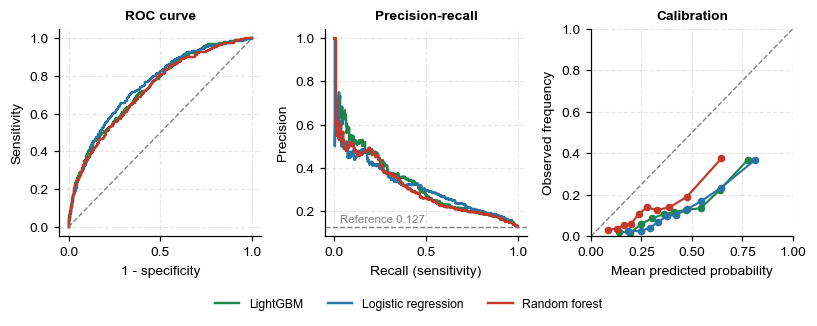

In [7]:
# Three compact panels share a single legend.
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.9))
CC = {"Logistic regression": "#2874A6", "Random forest": "#C0392B",
      "LightGBM": "#1E8449"}

for name in cvtab.index:
    p = probs[name]
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, lw=1.6, color=CC.get(name, "#7F8C8D"), label=name)
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, lw=1.6, color=CC.get(name, "#7F8C8D"))
    frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(mean_p, frac, marker="o", ms=4, lw=1.4,
                 color=CC.get(name, "#7F8C8D"))

axes[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=.9)
axes[0].set(xlabel="1 - specificity", ylabel="Sensitivity", title="ROC curve")

axes[1].axhline(y_te.mean(), ls="--", c="grey", lw=.9)
axes[1].text(0.03, y_te.mean() + 0.02, f"Reference {y_te.mean():.3f}",
             fontsize=7.5, color="grey")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision",
            title="Precision-recall")

# Use the full probability range so that this panel shares the axis limits of
# the ROC and precision-recall panels.
axes[2].plot([0, 1], [0, 1], ls="--", c="grey", lw=.9)
axes[2].set(xlabel="Mean predicted probability", ylabel="Observed frequency",
            title="Calibration", xlim=(0, 1), ylim=(0, 1))

for ax in axes:
    ax.grid(ls="--", alpha=.3); ax.set_axisbelow(True)
    ax.title.set_fontsize(9); ax.title.set_fontweight("bold")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, frameon=False, fontsize=8,
           loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=[0, 0.07, 1, 1])
save_fig(fig, "Fig4_model_performance"); plt.show()


## 7. Temporal validation


In [8]:
ROB_KEYS = ["ROC-AUC", "PR-AUC", "Average precision", "Brier"]

def rob_row(label, y_true, p, thr):
    y_true = np.asarray(y_true)
    m = metric_block(y_true, p, thr)
    ci = boot_ci(y_true, p, thr, ROB_KEYS)
    return {
        "Analysis": label,
        "n": f"{len(y_true):,}",
        "MetS, n (%)": f"{int(y_true.sum()):,} ({y_true.mean()*100:.2f})",
        **{
            k: (
                f"{fmt_metric(k, m[k])} "
                f"({fmt_metric(k, ci[k][0])}, {fmt_metric(k, ci[k][1])})"
            )
            for k in ROB_KEYS
        },
    }

rob = [rob_row("Primary held-out test set", y_te, probs[FINAL_NAME], FINAL_THR)]

# Temporal validation: all tuning is repeated on 2021-2023 only.
tr_mask = df["year"].isin([2021, 2022, 2023])
te_mask = df["year"].eq(2024)
Xa, ya = X.loc[tr_mask], y.loc[tr_mask]
Xb, yb = X.loc[te_mask], y.loc[te_mask]
assert len(Xa) and len(Xb), "temporal split is empty; check year coding"

temp_cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
rf_est, rf_space = CANDIDATES[FINAL_NAME]
search_t, best_t, oof_t, thr_t = tune_estimator(
    clone(rf_est), rf_space, Xa, ya, temp_cv
)
p_t = best_t.predict_proba(Xb)[:, 1]
rob.append(rob_row(
    "Temporal: tuned/trained on 2021-2023, tested on 2024",
    yb, p_t, thr_t
))
print(f"Temporal RF search used {search_t.n_iter} training-only configurations.")

temporal = pd.DataFrame(rob)
pd.set_option("display.width", 260, "display.max_colwidth", 62)
print("\n=== Temporal validation (Editor 7) ===")
print(temporal.to_string(index=False))
temporal.to_csv(
    OUT_T/"temporal_validation.csv",
    index=False, encoding="utf-8-sig"
)


Temporal RF search used 40 training-only configurations.

=== Temporal validation (Editor 7) ===
                                            Analysis     n MetS, n (%)              ROC-AUC               PR-AUC    Average precision                   Brier
                           Primary held-out test set 2,734 346 (12.66) 0.724 (0.695, 0.753) 0.308 (0.261, 0.362) 0.309 (0.264, 0.365) 0.1334 (0.1273, 0.1392)
Temporal: tuned/trained on 2021-2023, tested on 2024 3,349 453 (13.53) 0.751 (0.727, 0.777) 0.338 (0.296, 0.385) 0.340 (0.299, 0.389) 0.1343 (0.1288, 0.1397)


## 8. SHAP — Fig 6 and feature-importance table

SHAP shape: (2734, 19) | X: (2734, 19)
  saved -> Fig6_shap_summary.tif / .png


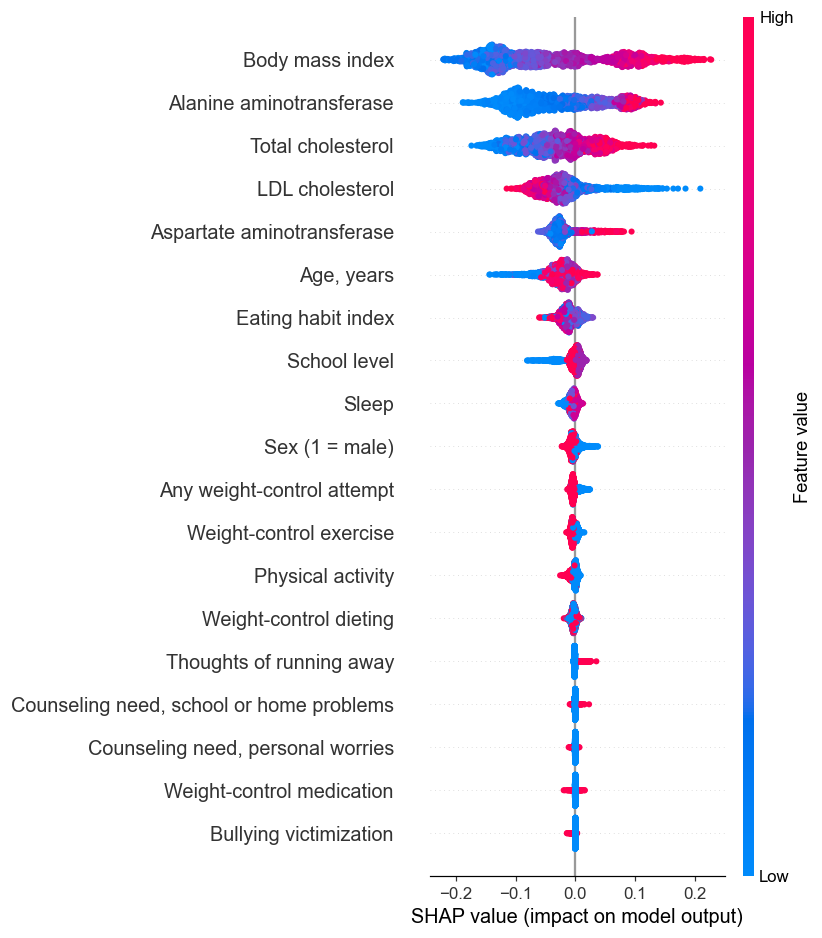

                                 Feature                  Variable  Mean |SHAP|  Mean SHAP
                         Body mass index                       bmi      0.10017   -0.04559
                Alanine aminotransferase                       ALT      0.07006   -0.03075
                       Total cholesterol                      chol      0.05348   -0.03237
                         LDL cholesterol                       LDL      0.03846   -0.02111
              Aspartate aminotransferase                       AST      0.02837   -0.02004
                              Age, years                       age      0.02628   -0.02469
                      Eating habit index               EatingIndex      0.01390   -0.01067
                            School level              global_grade      0.00881   -0.00295
                                   Sleep                     sleep      0.00618   -0.00501
                          Sex (1 = male)                       sex      0.00599   -0.00198

In [9]:
import shap

expl_model = (fitted[FINAL_NAME].named_steps["clf"]
              if isinstance(fitted[FINAL_NAME], Pipeline) else fitted[FINAL_NAME])
X_shap = (pd.DataFrame(fitted[FINAL_NAME].named_steps["sc"].transform(X_te),
                       columns=FEATURES, index=X_te.index)
          if isinstance(fitted[FINAL_NAME], Pipeline) else X_te)

if FINAL_NAME == "Logistic regression":
    explainer = shap.LinearExplainer(expl_model, X_shap)
    sv_arr = explainer.shap_values(X_shap)
else:
    explainer = shap.TreeExplainer(expl_model)
    raw = explainer.shap_values(X_shap)
    sv_arr = raw[1] if isinstance(raw, list) else (
        raw[:, :, 1] if getattr(raw, "ndim", 2) == 3 else raw)

print("SHAP shape:", np.shape(sv_arr), "| X:", X_shap.shape)

# Plot with readable labels rather than the raw column names.
X_plot = X_shap.rename(columns=DISPLAY_NAME)

plt.figure(figsize=(7.5, 8.6))
shap.summary_plot(sv_arr, X_plot, plot_type="dot", show=False,
                  max_display=19)

# summary_plot sets its own figure size, one row per feature, and so replaces
# the size given above. For nineteen features that comes to 8.0 by 9.1 inches,
# which at 300 dpi is 2,378 by 2,708 pixels. The journal accepts at most 2,250
# by 2,625 pixels, so the size is set again here, after the plot is drawn. The
# value matches Fig 1 and keeps every figure within the limit.
plt.gcf().set_size_inches(7.5, 8.6)

# The manuscript caption supplies the figure title.
plt.tight_layout(); save_fig(plt.gcf(), "Fig6_shap_summary"); plt.show()

imp = (pd.DataFrame({"Feature": [DISPLAY_NAME[c] for c in FEATURES],
                     "Variable": FEATURES,
                     "Mean |SHAP|": np.abs(sv_arr).mean(axis=0),
                     "Mean SHAP": np.asarray(sv_arr).mean(axis=0)})
       .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))
imp[["Mean |SHAP|", "Mean SHAP"]] = imp[["Mean |SHAP|", "Mean SHAP"]].round(5)
print(imp.to_string(index=False))
imp.to_csv(OUT_T/"shap_importance.csv", index=False, encoding="utf-8-sig")
print("\nsaved -> tables/shap_importance.csv")

## LDL cholesterol: unadjusted and adjusted direction

Editor 8 asked for the negative SHAP contribution of LDL cholesterol to be
clarified. The next cell reports the quantities used in the Discussion.


In [10]:
# =====================================================================
# LDL cholesterol: unadjusted and adjusted direction
#
# Editor 8 asked for the negative SHAP contribution of LDL cholesterol
# to be clarified.  In the SHAP summary plot the colors for LDL
# cholesterol are reversed relative to total cholesterol, while Table 1
# shows LDL cholesterol slightly higher among participants with
# metabolic syndrome.
#
# A SHAP value is a contribution conditional on the other features in
# the model, so it need not follow the direction of an unadjusted
# comparison.  This cell reports the three quantities used in the
# Discussion: the correlation between the two lipid measurements, the
# odds ratio for LDL cholesterol on its own, and the odds ratios for
# LDL cholesterol and total cholesterol when both are in the model.
#
# Editor 10 asked for effect estimates with confidence intervals, so
# each odds ratio is reported with a 95% confidence interval from the
# same number of bootstrap resamples used elsewhere in this notebook.
#
# Only summary statistics are printed or saved.  No participant-level
# record leaves this cell.
#
# Paste this cell after the SHAP cell in notebook 05.
# =====================================================================

# ---------------------------------------------------------------------
# 1. How closely the two lipid measurements track each other
# ---------------------------------------------------------------------
pearson_tc_ldl = df["chol"].corr(df["LDL"], method="pearson")

print("=" * 70)
print("LDL CHOLESTEROL: UNADJUSTED AND ADJUSTED DIRECTION")
print("=" * 70)
print()
print("Analytic sample    : %d participants" % len(df))
print("Metabolic syndrome : %d (%.2f%%)" % (int(y.sum()), y.mean() * 100))
print("Correlation between total cholesterol and LDL cholesterol:"
      " Pearson r = %.2f" % pearson_tc_ldl)
print()


# ---------------------------------------------------------------------
# 2. Two logistic regressions on the same participants
#
#    Model A : LDL cholesterol alone
#    Model B : LDL cholesterol together with total cholesterol
#
#    Each predictor is standardized first, so an odds ratio refers to a
#    difference of one standard deviation.  The penalty is made very
#    weak because the aim is to read the coefficients rather than to
#    build a predictive model.
# ---------------------------------------------------------------------
def logistic_odds_ratios(frame, columns, outcome):
    """Fit a logistic regression and return one odds ratio per column."""
    scaler = StandardScaler()
    design = scaler.fit_transform(frame[columns])
    model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=5000)
    model.fit(design, outcome)
    odds_ratios = {}
    for position, name in enumerate(columns):
        odds_ratios[name] = float(np.exp(model.coef_[0][position]))
    return odds_ratios


ldl_alone = logistic_odds_ratios(df, ["LDL"], y)
both_lipids = logistic_odds_ratios(df, ["chol", "LDL"], y)


# ---------------------------------------------------------------------
# 3. Confidence intervals, by resampling the participants
# ---------------------------------------------------------------------
generator = np.random.RandomState(SEED)
row_count = len(df)
lipids = df[["chol", "LDL"]].reset_index(drop=True)
outcome = y.reset_index(drop=True)

boot_ldl_alone = []
boot_chol_both = []
boot_ldl_both = []

for draw in range(N_BOOT):
    rows = generator.randint(0, row_count, row_count)
    sample_lipids = lipids.iloc[rows]
    sample_outcome = outcome.iloc[rows]
    if sample_outcome.nunique() < 2:
        continue
    sample_alone = logistic_odds_ratios(sample_lipids, ["LDL"], sample_outcome)
    sample_both = logistic_odds_ratios(sample_lipids, ["chol", "LDL"],
                                       sample_outcome)
    boot_ldl_alone.append(sample_alone["LDL"])
    boot_chol_both.append(sample_both["chol"])
    boot_ldl_both.append(sample_both["LDL"])


def confidence_interval(values):
    """The 2.5th and 97.5th percentiles of the bootstrap distribution."""
    return np.percentile(np.array(values), [2.5, 97.5])


ldl_alone_low, ldl_alone_high = confidence_interval(boot_ldl_alone)
chol_both_low, chol_both_high = confidence_interval(boot_chol_both)
ldl_both_low, ldl_both_high = confidence_interval(boot_ldl_both)

print("Odds ratios per standard deviation, with 95%% confidence intervals"
      " from %d bootstrap resamples" % len(boot_ldl_both))
print()
print("  LDL cholesterol alone")
print("    LDL cholesterol   %.2f  (%.2f, %.2f)"
      % (ldl_alone["LDL"], ldl_alone_low, ldl_alone_high))
print()
print("  LDL cholesterol and total cholesterol together")
print("    total cholesterol %.2f  (%.2f, %.2f)"
      % (both_lipids["chol"], chol_both_low, chol_both_high))
print("    LDL cholesterol   %.2f  (%.2f, %.2f)"
      % (both_lipids["LDL"], ldl_both_low, ldl_both_high))
print()


# ---------------------------------------------------------------------
# 4. Save the three quantities reported in the Discussion
# ---------------------------------------------------------------------
summary_rows = [
    ("Correlation between total cholesterol and LDL cholesterol, Pearson r",
     "%.2f" % pearson_tc_ldl, ""),
    ("LDL cholesterol alone, odds ratio per standard deviation",
     "%.2f" % ldl_alone["LDL"],
     "(%.2f, %.2f)" % (ldl_alone_low, ldl_alone_high)),
    ("Total cholesterol with LDL cholesterol in the model,"
     " odds ratio per standard deviation",
     "%.2f" % both_lipids["chol"],
     "(%.2f, %.2f)" % (chol_both_low, chol_both_high)),
    ("LDL cholesterol with total cholesterol in the model,"
     " odds ratio per standard deviation",
     "%.2f" % both_lipids["LDL"],
     "(%.2f, %.2f)" % (ldl_both_low, ldl_both_high)),
]

ldl_check = pd.DataFrame(summary_rows,
                         columns=["Quantity", "Value", "95% CI"])
ldl_check.to_csv(OUT_T / "ldl_direction_check.csv", index=False,
                 encoding="utf-8-sig")
print(ldl_check.to_string(index=False))
print()
print("saved -> tables/ldl_direction_check.csv")

LDL CHOLESTEROL: UNADJUSTED AND ADJUSTED DIRECTION

Analytic sample    : 13670 participants
Metabolic syndrome : 1730 (12.66%)
Correlation between total cholesterol and LDL cholesterol: Pearson r = 0.88

Odds ratios per standard deviation, with 95% confidence intervals from 2000 bootstrap resamples

  LDL cholesterol alone
    LDL cholesterol   1.06  (1.00, 1.12)

  LDL cholesterol and total cholesterol together
    total cholesterol 3.07  (2.75, 3.46)
    LDL cholesterol   0.40  (0.36, 0.45)

                                                                              Quantity Value       95% CI
                  Correlation between total cholesterol and LDL cholesterol, Pearson r  0.88             
                              LDL cholesterol alone, odds ratio per standard deviation  1.06 (1.00, 1.12)
Total cholesterol with LDL cholesterol in the model, odds ratio per standard deviation  3.07 (2.75, 3.46)
LDL cholesterol with total cholesterol in the model, odds ratio per standard 

## 9. Fig 5 — calibration before and after

  saved -> Fig5_calibration_before_after.tif / .png


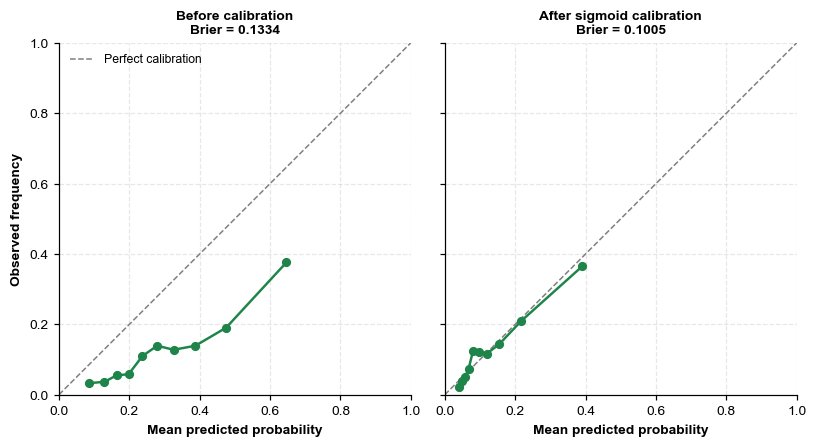

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 4.3), sharex=True, sharey=True)
for ax, (p, title) in zip(axes, [(probs[FINAL_NAME], "Before calibration"),
                                 (p_cal, f"After {BEST_CAL} calibration")]):
    frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="Perfect calibration")
    ax.plot(mean_p, frac, marker="o", ms=5, lw=1.6, color="#1E8449")
    ax.set_title(f"{title}\nBrier = {brier_score_loss(y_te, p):.4f}",
                 fontweight="bold", fontsize=9)
    ax.set_xlabel("Mean predicted probability", fontweight="bold", fontsize=9)
    ax.grid(ls="--", alpha=.3); ax.set_axisbelow(True)
    # Draw each panel as a square so that the diagonal appears at 45 degrees.
    ax.set_box_aspect(1)
axes[0].set_ylabel("Observed frequency", fontweight="bold", fontsize=9)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); save_fig(fig, "Fig5_calibration_before_after"); plt.show()

## 10. Table 3 — final model performance and reproducibility specification

In [12]:
# Full specification of the retained final algorithm.
bp = dict(sorted(
    (k.replace("clf__", ""), v)
    for k, v in results[FINAL_NAME]["best_params"].items()
))

spec = [("Algorithm", FINAL_NAME)]
spec += [(k, str(v)) for k, v in bp.items()]
spec += [
    ("class_weight", "balanced"),
    (
        "Hyperparameter search",
        f"RandomizedSearchCV, {int(results[FINAL_NAME]['search_draws'])} unique "
        f"configurations for the final Random Forest, {CV_FOLDS}-fold stratified "
        "cross-validation within the training set, scoring = average precision (AP)"
    ),
    ("Final-algorithm rationale", MODEL_SELECTION_RATIONALE),
    (
        "Recalibration",
        f"{BEST_CAL.capitalize()} regression selected by the lower out-of-fold "
        "training Brier score among isotonic and sigmoid calibration; fitted "
        "without using the test set for method selection"
    ),
    (
        "Classification threshold, before recalibration",
        f"{FINAL_THR:.2f} (F1-maximizing, out-of-fold training predictions)"
    ),
    (
        "Classification threshold, final recalibrated model",
        f"{THR_CAL:.2f} (F1-maximizing, out-of-fold training predictions)"
    ),
    ("Random seed", str(SEED)),
    ("Software", "scikit-learn, LightGBM and SHAP, Python 3.9"),
]

spec_table = pd.DataFrame(spec, columns=["Item", "Value"])
pd.set_option("display.max_colwidth", 100)
print(spec_table.to_string(index=False))
spec_table.to_csv(
    OUT_T/"final_model_specification.csv",
    index=False, encoding="utf-8-sig"
)

print("\n--- Suggested table footnotes ---")
print(
    "Table 2: Hyperparameters were optimized within the training set using "
    "RandomizedSearchCV with five-fold stratified cross-validation and average "
    "precision as the search score. Average precision is reported separately "
    "from trapezoidal PR-AUC."
)
print(
    f"Table 3: {BEST_CAL.capitalize()} recalibration was selected using only "
    "out-of-fold training predictions. The final classification threshold was "
    "then selected by maximizing F1 in those training predictions."
)

# Table 3: recalibrated final model.
m_cal = METRICS[FINAL_LABEL]
ci_cal = boot_ci(y_te, p_cal, THR_CAL, CI_KEYS)

perf = [
    (
        k,
        f"{fmt_metric(k, m_cal[k])} "
        f"({fmt_metric(k, ci_cal[k][0])}, {fmt_metric(k, ci_cal[k][1])})"
    )
    for k in CI_KEYS
]
perf += [
    ("Confusion (TP/FP/TN/FN)",
     f"{m_cal['TP']}/{m_cal['FP']}/{m_cal['TN']}/{m_cal['FN']}"),
    ("F1", f"{m_cal['F1']:.3f}"),
    ("Negative predictive value", f"{m_cal['NPV']:.3f}"),
]

table3 = pd.DataFrame(
    perf,
    columns=[
        "Measure",
        f"{FINAL_NAME}, {BEST_CAL}-recalibrated (threshold {THR_CAL:.2f})"
    ]
)
print(
    f"\n=== Table 3. Final model on the test set "
    f"(n = {n_te:,}; 95% CI from {N_BOOT:,} bootstrap resamples) ==="
)
print(table3.to_string(index=False))
table3.to_csv(
    OUT_T/"Table3_final_model_performance.csv",
    index=False, encoding="utf-8-sig"
)

# Reference values remain in a separate table because they correspond to
# different reference strategies.
print("\nReference values:")
print(reference_values.to_string(index=False))


                                              Item                                                                                                                                                                    Value
                                         Algorithm                                                                                                                                                            Random forest
                                         criterion                                                                                                                                                                  entropy
                                         max_depth                                                                                                                                                                     None
                                      max_features                                                                      

## 11. Submission summary and consistency checks

In [13]:
print("=" * 72)
print("MODEL RESULTS / CONSISTENCY CHECKS")
print("=" * 72)
print(f"Analytic sample     : {len(df):,} (MetS {int(y.sum()):,}, {y.mean()*100:.2f}%)")
print(f"Split               : 80:20 stratified, seed {SEED}")
print(f"Test set            : {len(y_te):,} (MetS {int(y_te.sum()):,})")
print(f"Final algorithm     : {FINAL_NAME}")
print(f"Calibration method  : {BEST_CAL} (selected from training OOF Brier)")
print(f"Threshold           : {THR_CAL:.2f} (selected within training data)")
print(f"Top 5 SHAP features : {', '.join(imp.Feature.head(5))}")

print("\nInterpretation safeguards")
print("  * AP (search score) and trapezoidal PR-AUC are distinct quantities.")
print("  * Metric-specific reference values are reported separately.")
print("  * Temporal validation re-tunes using 2021-2023 only before testing 2024.")
print("  * SHAP values describe model contributions, not causal effects.")
print("  * The model includes biochemical predictors and is not a tool for deciding")
print("    who should receive those biochemical tests.")
print("  * External/prospective validation has not been performed.")


MODEL RESULTS / CONSISTENCY CHECKS
Analytic sample     : 13,670 (MetS 1,730, 12.66%)
Split               : 80:20 stratified, seed 42
Test set            : 2,734 (MetS 346)
Final algorithm     : Random forest
Calibration method  : sigmoid (selected from training OOF Brier)
Threshold           : 0.18 (selected within training data)
Top 5 SHAP features : Body mass index, Alanine aminotransferase, Total cholesterol, LDL cholesterol, Aspartate aminotransferase

Interpretation safeguards
  * AP (search score) and trapezoidal PR-AUC are distinct quantities.
  * Metric-specific reference values are reported separately.
  * Temporal validation re-tunes using 2021-2023 only before testing 2024.
  * SHAP values describe model contributions, not causal effects.
  * The model includes biochemical predictors and is not a tool for deciding
    who should receive those biochemical tests.
  * External/prospective validation has not been performed.


---

## Methods text supported by this notebook

Three candidate algorithms were evaluated: logistic regression, Random Forest,
and LightGBM. The data were divided into training (80%) and test (20%) sets
using outcome-stratified sampling. Feature scaling for logistic regression,
hyperparameter optimization, and classification-threshold selection were
performed within the training data. The test set was reserved for performance
evaluation.

Hyperparameters were optimized with RandomizedSearchCV and five-fold stratified
cross-validation. The search score was **average precision (AP)**. Because AP
is not identical to the trapezoidal area under the empirical precision-recall
curve, the notebook reports AP and PR-AUC separately. The number of randomized
draws is capped by the number of unique configurations in each search space;
therefore, logistic regression is not described as having 40 draws when only
20 unique configurations exist.

Random Forest is retained as the final algorithm in the revised analysis on
methodological grounds rather than because it achieved the highest
cross-validated performance estimate. Its probability-recalibration method is
selected using out-of-fold training Brier score only, and the final
classification threshold is selected by maximizing F1 in out-of-fold training
predictions. Neither decision uses the held-out test outcomes.

Performance is reported using ROC-AUC, trapezoidal PR-AUC, average precision,
accuracy, precision, recall/sensitivity, specificity, F1 score, negative
predictive value, and Brier score. Confidence intervals are obtained by 2,000
bootstrap resamples of the test set. Reference values are metric-specific:
all-negative accuracy and constant-prevalence Brier score are not combined into
a single reference-model row.

Temporal validation repeats hyperparameter tuning using 2021–2023 records only
and then evaluates the resulting model on 2024.

The model includes total cholesterol, LDL cholesterol, AST, and ALT, so it is
not interpreted as a tool for deciding which students should receive those
tests.
